# Reconstruct: 1 イベント 1 行の再構成ツリー

それまでのモジュールの結果をまとめ、**全イベントで 1 行**のツリー `Reconstruct/single_hit` を作ります。
SMILE_tool_box の `Reconstruct`(ツリー `s2t`)と同じ並び・同じ更新規則です。

### `err_flag` と値の更新規則

| 条件 | `err_flag` | 書かれる値 |
|---|---|---|
| Ee・Eg が有効、電子方向 Ve_TRA あり | 0 | すべて新しい値。運動学の角度も計算 |
| Ee・Eg が有効、Ve_TRA なし | 前の行のまま | `Ke`, `Eg`, `Pg` などは新しい値、角度は前の行のまま、`Ve_TRA_fit_status` は 1 |
| それ以外 | 1 | 角度・`Ve_TRA`・`Track_Min/Max` はセンチネル(`0xffffffff`)、`Eg`, `Ke`, `Pg` は**前の行のまま** |

参照と行単位で一致させるため、この(少し癖のある)規則をそのまま再現しています。
**解析には `err_flag == 0` の行だけを使ってください。**

### 運動学

`Eg`, `Ke` から、散乱角 `phi_kin`、反跳角 `psi_kin`、散乱ガンマ線と反跳電子のなす角 `alpha_kin` [deg] を求めます
(`m_e c^2 = 510.9989461 keV`)。

$$\cos\phi = 1 - \frac{m_e c^2}{E_g + K_e}\frac{K_e}{E_g},\quad
\cos\psi = \left(1 + \frac{m_e c^2}{E_g + K_e}\right)\sqrt{\frac{K_e}{K_e + 2 m_e c^2}},\quad
\cos\alpha = \left(1 - \frac{m_e c^2}{E_g}\right)\sqrt{\frac{K_e}{K_e + 2 m_e c^2}}$$

In [1]:
import sys, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ROOT
ROOT.gROOT.SetBatch(True)

# リポジトリの場所、チェーンの実行スクリプト、設定ファイル(config/*.json)の読み込み
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CACHE = REPO / "tutorials" / "cache"   # チェーンの出力の置き場(チュートリアル間で共有)
CACHE.mkdir(exist_ok=True)

def vec(column):
    """RDataFrame.AsNumpy() の配列型の列 -> 2 次元の numpy 配列"""
    return np.stack([np.asarray(v) for v in column])

## 1. データの準備

データ(20190701 の較正データ **Per02**)の入手方法と置き場所は、
**[1_DataIO のノートブック](../../DataIO_example.ipynb) の「1. データのダウンロード」**を見てください。
1_DataIO の手順でデータを置いていれば、ここでは何もする必要はありません。

下のセルで、設定ファイル `config/smile2p_20190701_Per02.json` が指すデータが見つかるかだけ確認します
(`MISSING` と出たら 1_DataIO の 1 節の手順でデータをコピーしてください)。

In [2]:
CONFIG = "smile2p_20190701_Per02"
cfg = ec.load(CONFIG)
print("data_top:", ec.data_top())
for path in [cfg["parameters"]["ReadData"]["data_dir"], cfg["parameters"]["HA_Calc"]["parameter_dir"]]:
    print("OK     " if Path(path).is_dir() else "MISSING", path)

data_top: /home/onoda/hikaru3_analysis2/sm2+_cal_rawdata
OK      /home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/Per02_ETCC
OK      /home/onoda/hikaru3_analysis2/sm2+_cal_rawdata/param/20190528


## 2. 全チェーンを実行する(DataIO と同じ出力を共有)

In [3]:
OUT = CACHE / "Per02_50000.root"
cmd = [sys.executable, str(RUN_CHAIN), CONFIG, "-o", str(OUT), "-n", "50000"]
print(" ".join(cmd))
if not OUT.exists():
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:])
    r.check_returncode()

/usr/bin/python3 /home/onoda/ANLNext/EricaNext_try/run_script/run_chain.py smile2p_20190701_Per02 -o /home/onoda/ANLNext/EricaNext_try/tutorials/cache/Per02_50000.root -n 50000


## 3. `err_flag` の内訳

In [4]:
df = ROOT.RDataFrame("Reconstruct/single_hit", str(OUT))
allrows = df.AsNumpy(["err_flag"])["err_flag"]
vals, counts = np.unique(allrows, return_counts=True)
for v, c in zip(vals, counts):
    print(f"err_flag = {v}: {c:6d} ({c / len(allrows):.1%})")

err_flag = 0:  26697 (53.4%)
err_flag = 1:  23303 (46.6%)


## 4. エネルギーと運動学

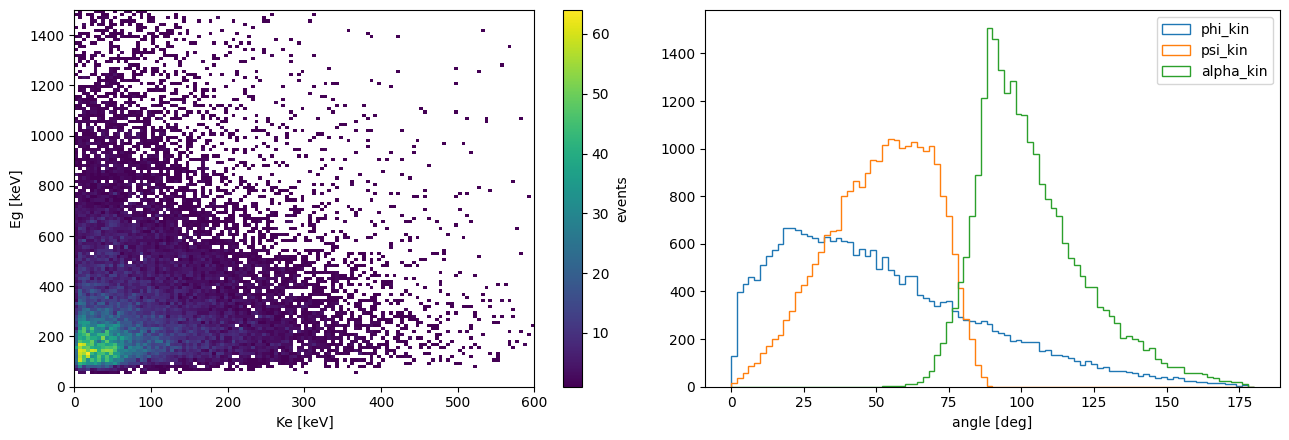

In [5]:
ev = df.Filter("err_flag == 0").AsNumpy(["Eg", "Ke", "phi_kin", "psi_kin", "alpha_kin"])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
h = ax[0].hist2d(ev["Ke"], ev["Eg"], bins=[120, 120], range=[[0, 600], [0, 1500]], cmin=1)
fig.colorbar(h[3], ax=ax[0], label="events")
ax[0].set_xlabel("Ke [keV]"); ax[0].set_ylabel("Eg [keV]")
for name in ["phi_kin", "psi_kin", "alpha_kin"]:
    x = ev[name]; ax[1].hist(x[(x >= 0) & (x <= 180)], bins=90, range=(0, 180), histtype="step", label=name)
ax[1].set_xlabel("angle [deg]"); ax[1].legend()
fig.tight_layout(); plt.show()